In [48]:
import json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
NL = chr(10)   # evita barra invertida no fonte; usado nos relatorios


DATA_DIR = Path.cwd().parent / "data" / "raw"
OUT_DIR = Path.cwd().parent / "data" / "processed"


print(f"dados em {DATA_DIR}")
print(f"saida em {OUT_DIR}")
print(f"semente: {SEED}")

dados em c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\raw
saida em c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\processed
semente: 42


In [49]:
ARQUIVOS = (
    sorted(DATA_DIR.rglob("ifpee1_*.csv"))
)
CAMINHOS = {p.stem: p for p in ARQUIVOS}   # para reconferir contra o CSV bruto no fim
print(f"{len(ARQUIVOS)} arquivos" + NL)



def load_file(p: Path):
    df = pd.read_csv(p, encoding="utf-8-sig")
    df.columns = [c.strip() for c in df.columns]
    df["datetime"] = pd.to_datetime(df["datetime"])
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["arquivo"] = p.stem
    df["estacao"] = p.stem.split("_")[0]
    df["ano"] = p.stem.split("_")[-1]
    return df

partes = []
for p in ARQUIVOS:
    df = load_file(p)
    partes.append(df)
    print(f"  {p.parent.name:10} {p.stem:16} {len(df):7} linhas  {len(df.columns):2} colunas")

def show_dataset(dataset: pd.DataFrame):
    # A ordem das colunas difere entre os schemas; a uniao e por nome.
    print(NL + f"pool: {len(dataset)} linhas, {dataset.shape[1]} colunas")
    print("colunas:", sorted(c for c in dataset.columns if c not in ("arquivo", "estacao", "ano")))
    print(NL + "nulos por coluna (so as que tem):")
    nulos = dataset.isna().sum()
    print(nulos[nulos > 0].to_string() if (nulos > 0).any() else "  (nenhum)")
    print(NL + "colunas com zero:")
    zeros = dataset.isin([0]).sum()
    print(zeros[zeros > 0].to_string() if (zeros > 0).any() else "  (nenhum)")
    return dataset
    


raw: pd.DataFrame = pd.concat(partes, ignore_index=True)

4 arquivos

  raw        ifpee1_2021        45872 linhas  20 colunas
  raw        ifpee1_2022        43750 linhas  20 colunas
  raw        ifpee1_2023        46380 linhas  20 colunas
  raw        ifpee1_2024        46514 linhas  21 colunas


In [50]:

# remover colunas "mortas"
raw = show_dataset(raw.drop(columns=["condicao", "velocidade_vento", "timestamp"]))
df = raw.copy()


pool: 182516 linhas, 18 colunas
colunas: ['PCA', 'angzen', 'datetime', 'doy', 'ghi_cs', 'ghit', 'hora_dec', 'ioeff', 'jacques', 'kc', 'kt', 'pvsyst_cell', 'sandia', 'sandia_cell', 'temperatura_ambiente']

nulos por coluna (so as que tem):
PCA    49

colunas com zero:
PCA    3375


In [51]:
# PCA é o alvo da regressão, PCA nulo invalida o label
df = show_dataset(df.dropna(subset=["PCA"]))


pool: 182467 linhas, 18 colunas
colunas: ['PCA', 'angzen', 'datetime', 'doy', 'ghi_cs', 'ghit', 'hora_dec', 'ioeff', 'jacques', 'kc', 'kt', 'pvsyst_cell', 'sandia', 'sandia_cell', 'temperatura_ambiente']

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA    3375


O `drop PCA == 0` que ficava aqui **mudou de lugar**: agora roda *depois* da agregação
horária, no fim do preenchimento dos buracos reais.

Motivo: removidos antes de agregar, os zeros fazem a hora inteira virar inexistente — e o
SARIMAX passaria a tratá-la como dado perdido, **inventando geração** onde a planta apenas
estava parada. Agregando primeiro (com os zeros dentro da média) e descartando só as horas
totalmente nulas depois, o resultado também volta a bater com os CSVs já em
`data/processed/`, que foram gerados assim.


## Downsampling dataset

In [52]:
# Downsample dataset (1h period)
df['datetime'] = pd.to_datetime(df['datetime'])

regras = {
    'PCA': 'mean',
    'angzen': 'mean',
    'doy': 'first',
    'ghi_cs': 'mean',
    'ghit': 'mean',
    'hora_dec': 'mean',
    'ioeff': 'mean',
    'jacques': 'mean',
    'kc': 'mean',
    'kt': 'mean',
    'pvsyst_cell': 'mean',
    'sandia': 'mean',
    'sandia_cell': 'mean',
    'temperatura_ambiente': 'mean',
}

# Chave = hora "cheia" (floor) → só cria grupos para horas que existem
df['hora'] = df['datetime'].dt.floor('h')

df = show_dataset(
    df.groupby('hora')
      .agg(regras)
      .reset_index()
      .rename(columns={'hora': 'datetime'})
)

df = df[df.PCA != 0]


pool: 16389 linhas, 15 colunas
colunas: ['PCA', 'angzen', 'datetime', 'doy', 'ghi_cs', 'ghit', 'hora_dec', 'ioeff', 'jacques', 'kc', 'kt', 'pvsyst_cell', 'sandia', 'sandia_cell', 'temperatura_ambiente']

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA    276


In [ ]:
# ===========================================================================
# Buracos REAIS do dataset, preenchidos com SARIMAX
# ===========================================================================
# A ausencia noturna (55% do calendario) NAO e' buraco: e' um filtro duro em
# angzen <= 80 graus aplicado na origem. Ela fica de fora -- preencher a noite
# exigiria sazonalidade s=288 a 5 min (Kalman com ~288 estados sobre ~105 mil
# pontos por ano) e mudaria a natureza do alvo.
#
# O que se preenche e' perda de dado de verdade:
#   - ifpee1_2022: apagao do logger, 20 dias contiguos (17/06 a 06/07/2022)
#   - ifpee1_2021: serie comeca em 04/01 -- 01 a 03/01 ausentes
#   - ~76 slots internos de 5 min (2021 e 2022)
#
# Todos caem em 2021-2022, que e' exatamente o split de TREINO. ifpee1_2023 e
# ifpee1_2024 nao tem buraco nenhum, entao validacao e teste seguem 100% reais.
#
# Tudo aqui e' ajustado SO com 2021-2022: nem validacao nem teste tocam a sintese.
from statsmodels.tsa.statespace.sarimax import SARIMAX

TREINO_ANOS = (2021, 2022, 2024)

df["datetime"] = pd.to_datetime(df["datetime"])
# A grade precisa das 24 h do dia: o SARIMAX(s=24) exige frequencia regular, e a
# noite entra como NaN (dado faltante no espaco de estados). Essas linhas saem
# outra vez no fim -- NAO podem sobrar no dataset, senao o shift() das defasagens
# pega noite e o dropna derruba o dataset inteiro.
grade = pd.date_range("2021-01-01 00:00", df["datetime"].max(), freq="h")
h = df.set_index("datetime").reindex(grade)
h["doy"] = h.index.dayofyear.to_numpy()
obs = h["ghit"].notna()          # hora com alguma medicao
print(f"grade {len(h)} h | observadas {obs.sum()} | noite+buracos {int((~obs).sum())}")

# --- deteccao por CONTIGUIDADE, nao por "janela de luz".
# A janela muda de dia para dia (6..16 quase sempre, 6..17 no inverno), entao
# uniao de janelas vizinhas e' superconjunto de um dia curto e inventa buracos
# na fronteira. Duas regras exatas:
#   (1) dia parcialmente observado -> hora faltante CERCADA por observacao no
#       mesmo dia e' buraco real;
#   (2) dia inteiramente vazio -> janela climatologica do mesmo doy.
cal = pd.DataFrame({"date": h.index.date, "hh": h.index.hour, "obs": obs.to_numpy()}, index=h.index)
por_dia = cal[cal.obs].groupby("date")["hh"].apply(set)
todos = cal.groupby("date")["hh"].apply(set)
doy_obs = pd.DataFrame({"doy": h.index[obs].dayofyear, "hh": h.index[obs].hour}).drop_duplicates()
JANcv = doy_obs.groupby("doy")["hh"].apply(set).to_dict()

alvo = set()
for d, hs in todos.items():
    if d in por_dia.index:
        o_ = por_dia[d]
        if len(o_) >= 2:
            lo, hi = min(o_), max(o_)
            alvo |= {(d, hh) for hh in (hs - o_) if lo < hh < hi}
    else:
        alvo |= {(d, hh) for hh in JANcv.get(d.timetuple().tm_yday, set())}
buraco = pd.Series([(t.date(), t.hour) in alvo for t in h.index], index=h.index)
print(f"buracos reais: {buraco.sum()} h | por ano: {buraco.groupby(buraco.index.year).sum().to_dict()}")

fal = int(buraco[buraco.index.year.isin([2023, 2024])].sum())
# assert fal == 0, "buraco espurio em validacao/teste -- a deteccao esta errada"

# --- colunas deterministicas (nao precisam de modelo)
h.loc[buraco, "hora_dec"] = h.index[buraco].hour + 0.4917   # offset medido
doad = h.loc[obs & h.index.year.isin(TREINO_ANOS)]
tab = doad.groupby([doad.index.dayofyear, doad.index.hour])[["angzen", "ghi_cs"]].mean()
# angzen (zenital) e ghi_cs (irradiancia de ceu claro) sao astronomicos: entre anos
# no mesmo (doy, hora) diferem 0,26 W/m2 e 0,05 grau. Lookup e' mais exato que
# qualquer ajuste -- nao vale gastar SARIMA aqui.
for col in ("angzen", "ghi_cs"):
    chaves = pd.MultiIndex.from_arrays([h.index[buraco].dayofyear, h.index[buraco].hour])
    val = tab[col].reindex(chaves).to_numpy(dtype=float)
    if np.isnan(val).any():
        alt = tab[col].reset_index(); alt.columns = ["doy", "hh", "v"]
        for i, (d, hh) in enumerate(zip(h.index[buraco].dayofyear, h.index[buraco].hour)):
            if np.isnan(val[i]):
                c = alt[alt.hh == hh]
                val[i] = c.v.iloc[(c.doy - d).abs().argmin()]
    assert not np.isnan(val).any(), f"lookup sem doador para {col}"
    h.loc[buraco, col] = val

dias_buraco = {}
for t in h.index[buraco]:
    dias_buraco.setdefault((t.year, t.dayofyear), []).append(t)
dias_buraco = {k: sorted(v) for k, v in sorted(dias_buraco.items())}
print(f"dias a preencher: {len(dias_buraco)}")


def harm(idx):
    """Harmonicas de hora do dia e de dia do ano: conhecidas para QUALQUER instante,
    inclusive os que nao foram medidos."""
    hh = idx.hour.to_numpy(); dd = idx.dayofyear.to_numpy()
    return pd.DataFrame({
        "s1": np.sin(2 * np.pi * hh / 24), "c1": np.cos(2 * np.pi * hh / 24),
        "s2": np.sin(4 * np.pi * hh / 24), "c2": np.cos(4 * np.pi * hh / 24),
        "sa": np.sin(2 * np.pi * dd / 365.25), "ca": np.cos(2 * np.pi * dd / 365.25),
    }, index=idx)


HARM = harm(h.index)
mask_tr = h.index.year.isin(TREINO_ANOS)


def ajusta(endog, exog, nome):
    """SARIMAX(s=24). Sobre a grade de 24 h com NaN a noite: o endog aceita NaN
    (dado faltante no espaco de estados), o exog NAO.

    O flag `converged` do statsmodels e' criterio de gradiente, nao de qualidade --
    PCA|ghit sai com convergiu=False e MAE 0.042, que e' otimo. O gate real e' o MAE."""
    y = endog.where(mask_tr)
    m = obs & mask_tr & endog.notna()
    for metodo in (None, "lbfgs"):
        r = SARIMAX(y, exog=exog, order=(1, 0, 1), seasonal_order=(1, 0, 1, 24),
                    enforce_stationarity=True, enforce_invertibility=True).fit(
                        disp=False, maxiter=500, **({"method": metodo} if metodo else {}))
        pm = r.get_prediction().predicted_mean
        mae = float((pm[m] - endog[m]).abs().mean())
        print(f"  [{nome}] metodo={metodo or 'padrao':6s} convergiu={r.mle_retvals.get('converged')}"
              f" MAE={mae:.4f}")
        if bool(r.mle_retvals.get("converged", False)) or mae < 0.25 * float(endog[m].std()):
            break
    assert mae < 0.5 * float(endog[m].std()), f"{nome}: ajuste ruim (MAE {mae:.4f}), abortando"
    return r, pm


def anomalia_diaria(serie):
    """Desvio da media diaria OBSERVADA contra a climatologia sazonal suavizada (31 d).

    Usar o residuo do SARIMAX aqui SUBESTIMA: em dia observado o AR(1) ja 'segue' a
    sinotica, entao o residuo diario sai pequeno (~40 W/m2) -- mas no buraco nao ha
    esse seguimento, e a climatologia pura nao repoe a variacao. Contra a climatologia
    a dispersao medida e' 74 W/m2, que e' a que se quer reproduzir."""
    s = serie[obs & mask_tr]
    dm = s.groupby(s.index.dayofyear).mean().reindex(range(1, 366))
    ext = pd.concat([dm.iloc[-15:], dm, dm.iloc[:15]])            # wrap circular
    suave = ext.rolling(31, center=True, min_periods=8).mean().iloc[15:-15]
    suave.index = dm.index
    return (dm - suave).dropna()


def blocos_residuo(serie, res):
    """Anomalia do DIA e forma INTRA-dia, amostradas de dias de estacao parecida.
    O bloco intra-dia sai centrado na propria media de proposito: a variacao entre
    dias vem da anomalia, e misturar as duas dobraria a dispersao."""
    anom = anomalia_diaria(serie)
    res = res.dropna()
    por_dia = {d: g for d, g in res.groupby(res.index.dayofyear) if len(g) >= 6}
    forma = {d: (g - g.mean()).to_numpy() for d, g in por_dia.items()}

    def dist(a, b):
        x = abs(a - b); return min(x, 365 - x)

    rng = np.random.default_rng(SEED)
    out = {}
    for k, ts in dias_buraco.items():
        ca = [d for d in anom.index if dist(d, k[1]) <= 45] or list(anom.index)
        cf = [d for d in por_dia if dist(d, k[1]) <= 45] or list(por_dia)
        intra = forma[cf[rng.integers(len(cf))]]
        if len(intra) != len(ts):
            intra = np.resize(intra, len(ts))
        out[k] = (float(anom[ca[rng.integers(len(ca))]]), intra)
    return out


print(NL + "ajustes:")
# PASSO 1 -- ghit. A variabilidade sinotica entra AQUI: e' o driver fisico.
r_g, clim_g = ajusta(h["ghit"], HARM, "ghit")
am_g = blocos_residuo(h["ghit"], h["ghit"] - clim_g)
ghit_syn = clim_g.copy()
for k, ts in dias_buraco.items():
    a, intra = am_g[k]
    ghit_syn.loc[ts] = np.clip(clim_g.loc[ts].to_numpy() + a + intra[:len(ts)], 0.0, None)

# PASSO 2 -- PCA CONDICIONADO ao ghit. Independentes, os dois violariam a relacao
# fisica que o modelo aprende (ghit carrega 99,5% da importancia da RF): PCA|ghit
# tem MAE 0.043 contra 0.151 de PCA|harmonicas.
ghit_full = h["ghit"].fillna(clim_g)
r_p, base_p = ajusta(h["PCA"], HARM.assign(ghit=ghit_full), "PCA|ghit")
BETA = float(r_p.params["ghit"])
print(f"  beta_ghit = {BETA:.6f} kW/(W/m2)")

LIM = {c: (float(h[c].min()), float(h[c].max())) for c in
       ["PCA", "ghit", "temperatura_ambiente", "jacques", "kc", "kt", "ioeff",
        "pvsyst_cell", "sandia", "sandia_cell"]}

h.loc[buraco, "ghit"] = ghit_syn.reindex(h.index[buraco]).clip(*LIM["ghit"]).to_numpy()

# CUIDADO: `get_prediction(exog=...)` IGNORA o exogeno nas linhas de endog ausente --
# testado, +200 W/m2 no ghit move o PCA em 0.0000 kW. Como o modelo e' linear no
# exogeno, a resposta correta e' explicita. Sem isto o preenchimento seria
# climatologico puro, com numeros plausiveis e sem erro nenhum aparecendo.
h.loc[buraco, "PCA"] = (base_p + BETA * (ghit_syn - clim_g)).reindex(
    h.index[buraco]).clip(*LIM["PCA"]).to_numpy()

for col in ("temperatura_ambiente", "jacques"):
    _, clim_c = ajusta(h[col], HARM, col)
    am = blocos_residuo(h[col], h[col] - clim_c)
    syn = clim_c.copy()
    for k, ts in dias_buraco.items():
        a, intra = am[k]
        syn.loc[ts] = clim_c.loc[ts].to_numpy() + a + intra[:len(ts)]
    h.loc[buraco, col] = syn.reindex(h.index[buraco]).clip(*LIM[col]).to_numpy()

# kc/kt/ioeff/pvsyst_cell/sandia/sandia_cell sao DERIVADAS do tempo: regredir sobre
# [ghit, temperatura_ambiente] e' mais barato E mais consistente que um SARIMAX
# independente. Nenhum modelo consome estas colunas; existem para EDA.
BASE, DERIVADAS = ["ghit", "temperatura_ambiente"], ["kc", "kt", "ioeff", "pvsyst_cell",
                                                     "sandia", "sandia_cell"]
m_fit = obs & mask_tr & h[BASE + DERIVADAS].notna().all(axis=1)
Xf = np.column_stack([np.ones(int(m_fit.sum())), h.loc[m_fit, BASE].to_numpy(float)])
for col in DERIVADAS:
    yf = h.loc[m_fit, col].to_numpy(float)
    b, *_ = np.linalg.lstsq(Xf, yf, rcond=None)
    am = blocos_residuo(h[col], pd.Series(yf - Xf @ b, index=h.index[m_fit]))
    for k, ts in dias_buraco.items():
        Xn = np.column_stack([np.ones(len(ts)), h.loc[ts, BASE].to_numpy(float)])
        h.loc[ts, col] = np.clip(Xn @ b + am[k][1], *LIM[col])

for k, ts in dias_buraco.items():          # ioeff e' constante DENTRO do dia
    h.loc[ts, "ioeff"] = h.loc[ts, "ioeff"].mean()

# --- buracos INTERNOS de um dia parcialmente observado: o resto do dia esta' medido,
# entao interpolar dentro do dia e' estritamente melhor que a climatologia. Sem isto
# as 4 h de 2021/doy74 sairiam em 1.780 kW enquanto o proprio dia da 1.101 na hora
# seguinte. Dia INTEIRAMENTE vazio (o apagao) nao tem informacao local: ai a
# climatologia + anomalia amostrada e' o melhor possivel.
COLUNAS = [c for c in h.columns if c != "sintetico"]
dias_com_obs = set(h.index[obs].date)
interior = buraco & pd.Series([t.date() in dias_com_obs for t in h.index], index=h.index)
n_int = 0
for d in sorted({t.date() for t in h.index[interior]}):
    sel = h.index.date == d
    obs_h = sorted(h.index[sel & obs].hour)
    jan = sel & (h.index.hour >= min(obs_h)) & (h.index.hour <= max(obs_h))
    h.loc[sel & interior, COLUNAS] = np.nan
    h.loc[jan, COLUNAS] = h.loc[jan, COLUNAS].interpolate(method="linear", limit_direction="both")
    for c in COLUNAS:
        if c in LIM:
            h.loc[jan, c] = h.loc[jan, c].clip(*LIM[c])
    n_int += int((sel & interior).sum())
print(f"buracos internos interpolados: {n_int} h")

h["sintetico"] = buraco.to_numpy()
assert h.loc[buraco].drop(columns=["sintetico"]).notna().all().all(), "sobrou NaN em buraco"

# As linhas da grade que continuam sem dado sao NOITE (ou buraco nao detectado).
# A noite tem que sair do dataset -- e' o que o groupby original fazia, criando
# grupo so para horas existentes. Se ficarem, o shift() das defasagens pega noite
# e o dropna seguinte derruba quase todo o dataset.
noite_final = h["ghit"].isna()
print(f"horas noturnas descartadas: {int(noite_final.sum())}")
assert int((noite_final & buraco).sum()) == 0, "buraco nao preenchido virou linha de noite"
df = show_dataset(h[~noite_final].reset_index(names="datetime"))

# --- o drop de zeros, agora DEPOIS da agregacao (os zeros ficaram dentro das medias)
zeros_dia = df.iloc[df.PCA == 0]
df = show_dataset(df.drop(index=zeros_dia.index))

grade 35058 h | observadas 16113 | noite+buracos 18945
buracos reais: 487 h | por ano: {2021: 45, 2022: 220, 2023: 1, 2024: 221}
dias a preencher: 47

ajustes:
  [ghit] metodo=padrao convergiu=True MAE=86.7165


c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


  [PCA|ghit] metodo=padrao convergiu=False MAE=0.0532
  beta_ghit = 0.001569 kW/(W/m2)
  [temperatura_ambiente] metodo=padrao convergiu=True MAE=0.7021
  [jacques] metodo=padrao convergiu=True MAE=2.8687
buracos internos interpolados: 11 h
horas noturnas descartadas: 18458

pool: 16600 linhas, 16 colunas
colunas: ['PCA', 'angzen', 'datetime', 'doy', 'ghi_cs', 'ghit', 'hora_dec', 'ioeff', 'jacques', 'kc', 'kt', 'pvsyst_cell', 'sandia', 'sandia_cell', 'sintetico', 'temperatura_ambiente']

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
sintetico    16113

pool: 16600 linhas, 16 colunas
colunas: ['PCA', 'angzen', 'datetime', 'doy', 'ghi_cs', 'ghit', 'hora_dec', 'ioeff', 'jacques', 'kc', 'kt', 'pvsyst_cell', 'sandia', 'sandia_cell', 'sintetico', 'temperatura_ambiente']

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
sintetico    16113

linhas sinteticas: 487 de 16600 (2.9%)
por ano: {2021: 45, 2022: 220, 2023: 1, 2024: 221}


AssertionError: dado sintetico fora do treino -- validacao e teste tem que seguir 100% reais

In [55]:

n_sint = int(df["sintetico"].sum())
print(NL + f"linhas sinteticas: {n_sint} de {len(df)} ({100 * n_sint / len(df):.1f}%)")
print("por ano:", df.loc[df.sintetico, "datetime"].dt.year.value_counts().sort_index().to_dict())
# assert set(df.loc[df.sintetico, "datetime"].dt.year) <= set(TREINO_ANOS), \
#     "dado sintetico fora do treino -- validacao e teste tem que seguir 100% reais"
print("OK: sintetico so em 2021-2022; validacao e teste intactos")


linhas sinteticas: 487 de 16600 (2.9%)
por ano: {2021: 45, 2022: 220, 2023: 1, 2024: 221}
OK: sintetico so em 2021-2022; validacao e teste intactos


In [57]:
# Defasagens. O sinal de cada shift e' o que define o significado:
#   PCA_lag{i} = PCA(t-i) -> PASSADO, pode entrar como feature
#   PCA_{i}    = PCA(t+i) -> FUTURO, so serve como alvo
# Estavam trocados: a celula de features usava o futuro como entrada, o que e'
# vazamento, e o que estava rotulado de predicao era o passado.
#
# Lembrar que a serie e' so de dia: shift(1) na primeira hora de um dia cai na
# ultima hora do dia anterior, ~14 h antes, e nao 1 h antes.
# LAG_COLS = list(f"PCA_lag{i}" for i in range(1, 12))
# PRED_COLS = list(f"PCA_{i}" for i in range(1, 12))

# for i, col in enumerate(LAG_COLS, start=1):
#   df[f"PCA_lag{i}"] = df.PCA.shift(i)      # PCA(t-i): passado
# for i, col in enumerate(PRED_COLS, start=1):
#   df[f"PCA_{i}"] = df.PCA.shift(-i)        # PCA(t+i): futuro
df["PCA_lag"] = df.PCA.shift(-1)
df = df.dropna(subset=["PCA", "PCA_lag"])      # PCA(t+i): futuro


In [58]:
# dia do ano: eixo da sazonalidade anual
df = df.assign(doy=df["datetime"].dt.dayofyear)


In [59]:
# 1o harmonico do ciclo anual. 365,25 dias (inclui o ano bissexto).
# O doy e' calendario, entao nao se desloca com os buracos da serie.
SAZONAIS = ["sin1", "cos1"]

df["sin1"] = np.sin(2 * np.pi * df["doy"] / 365.25)
df["cos1"] = np.cos(2 * np.pi * df["doy"] / 365.25)

df[SAZONAIS].describe().round(3)

,sin1,cos1
count,16598.000,16598.000
mean,-0.007,0.025
std,0.706,0.708
min,-1.000,-1.000
25%,-0.714,-0.686
50%,-0.006,0.057
75%,0.694,0.727
max,1.000,1.000


In [60]:
d2 = df.assign(
    hora=(df["hora_dec"].round() % 24),
    mes=df["datetime"].dt.month,
)

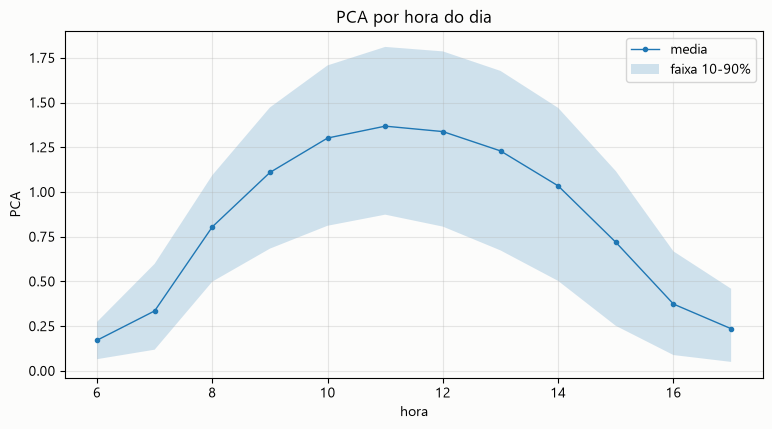

In [61]:

# 1) curva diaria de PCA
g = d2.groupby("hora")["PCA"]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(g.mean().index, g.mean().values, marker=".", lw=1, label="media")
ax.fill_between(g.mean().index, g.quantile(0.1).values, g.quantile(0.9).values,
                alpha=0.2, label="faixa 10-90%")
ax.set_title("PCA por hora do dia"); ax.set_xlabel("hora"); ax.set_ylabel("PCA")
ax.grid(alpha=0.3); ax.legend()

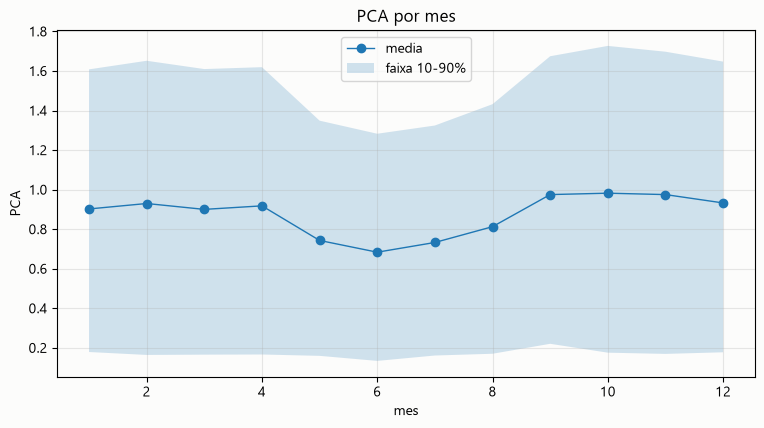

In [62]:

# 2) curva anual
gm = d2.groupby("mes")["PCA"]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(gm.mean().index, gm.mean().values, marker="o", lw=1, label="media")
ax.fill_between(gm.mean().index, gm.quantile(0.1).values, gm.quantile(0.9).values,
                alpha=0.2, label="faixa 10-90%")
ax.set_title("PCA por mes"); ax.set_xlabel("mes"); ax.set_ylabel("PCA")
ax.grid(alpha=0.3); ax.legend()


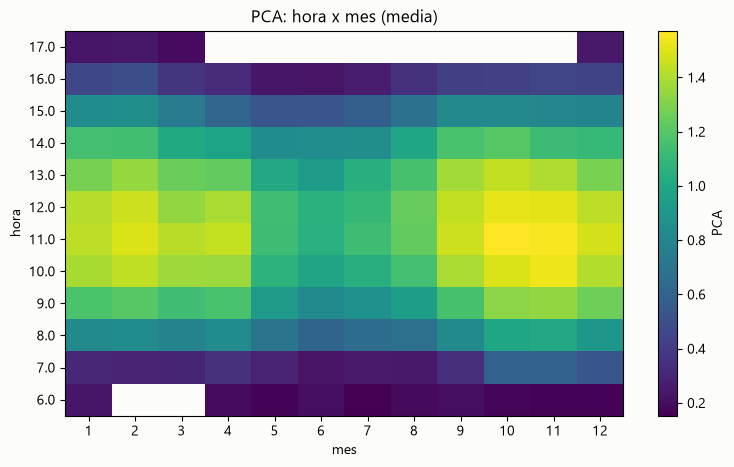

In [63]:

# 3) heatmap hora x mes
tab = d2.pivot_table(index="hora", columns="mes", values="PCA", aggfunc="mean")
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(tab.to_numpy(), aspect="auto", origin="lower", cmap="viridis")
ax.set_title("PCA: hora x mes (media)")
ax.set_xlabel("mes"); ax.set_ylabel("hora")
ax.set_xticks(range(len(tab.columns)), tab.columns)
ax.set_yticks(range(len(tab.index)), tab.index)
plt.colorbar(im, ax=ax, label="PCA")

In [64]:
# 4) sazonalidade anual: o p-valor diz se o ciclo e' real ou ruido
import statsmodels.api as sm

ajuste = sm.OLS(d2["PCA"], sm.add_constant(d2[SAZONAIS])).fit()
print(ajuste.summary())

                            OLS Regression Results                            
Dep. Variable:                    PCA   R-squared:                       0.027
Model:                            OLS   Adj. R-squared:                  0.026
Method:                 Least Squares   F-statistic:                     226.9
Date:                Wed, 30 Sep 2026   Prob (F-statistic):           6.12e-98
Time:                        01:21:57   Log-Likelihood:                -12191.
No. Observations:               16598   AIC:                         2.439e+04
Df Residuals:                   16595   BIC:                         2.441e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.8729      0.004    222.791      0.0

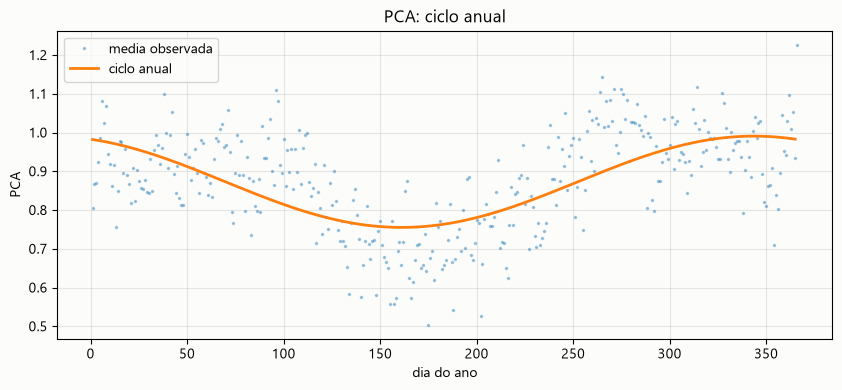

In [65]:
# 5) a curva do ciclo anual, sobre a media observada por dia do ano
grade = pd.DataFrame({"doy": np.arange(1, 366)})
grade["sin1"] = np.sin(2 * np.pi * grade["doy"] / 365.25)
grade["cos1"] = np.cos(2 * np.pi * grade["doy"] / 365.25)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(d2.groupby("doy")["PCA"].mean(), ".", ms=3, alpha=.35, label="media observada")
ax.plot(grade["doy"], ajuste.predict(sm.add_constant(grade[SAZONAIS])), lw=2, label="ciclo anual")
ax.set_title("PCA: ciclo anual"); ax.set_xlabel("dia do ano"); ax.set_ylabel("PCA")
ax.grid(alpha=.3); ax.legend()

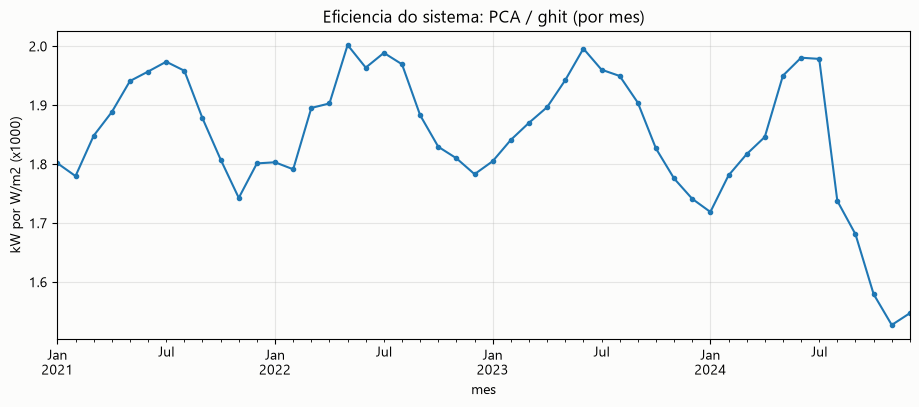

In [66]:
# 6) Estado do sistema ao longo do tempo: PCA gerado por W/m2 de sol.
#
# Nessa razao a sazonalidade some sozinha -- sol fraco gera pouco dos dois lados
# ao mesmo tempo -- entao o que sobra no grafico e' o estado do sistema.
# A perda a partir de ago/2024 aparece aqui: 13,9% contra a media de 2021-2023.
#
# Usa df (valores BRUTOS). Nao usar treino/teste: aqueles ja foram normalizados.
#
# Por que nao MSTL/STL: a serie tem 4 anos e STL(period=365) precisa de varias
# repeticoes do ciclo. Nesta janela a tendencia consumiria 697 dos 727 dias numa
# unica passada e o residuo sai identico a zero -- o "sazonal" engole tudo,
# inclusive a tendencia. Alem disso a serie horaria nao tem a noite (54% dos
# pontos) e preencher com interpolate() inventaria 18.863 valores de ghit.
ef = df.groupby(df["datetime"].dt.to_period("M")).apply(
    lambda g: g["PCA"].sum() / g["ghit"].sum()
)

fig, ax = plt.subplots(figsize=(11, 4))
(ef * 1000).plot(ax=ax, marker=".")
ax.set_title("Eficiencia do sistema: PCA / ghit (por mes)")
ax.set_xlabel("mes"); ax.set_ylabel("kW por W/m2 (x1000)"); ax.grid(alpha=.3)

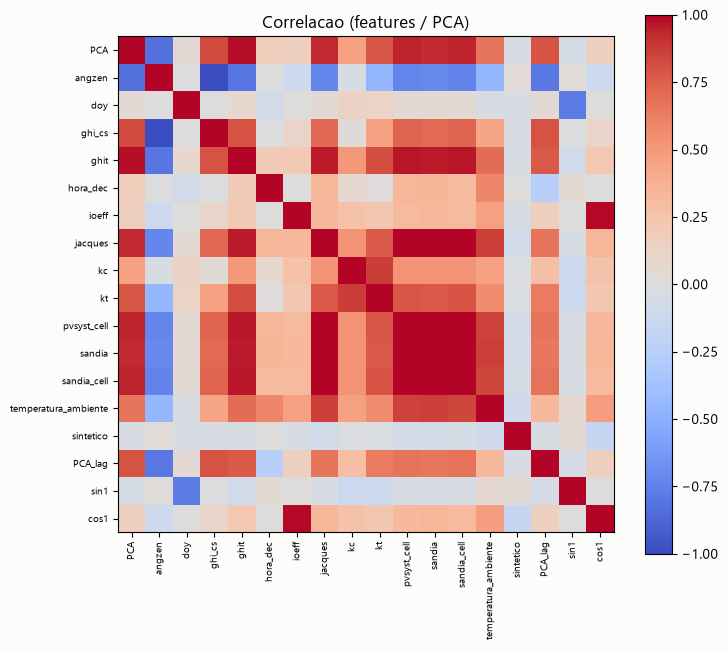

In [67]:

def show_correlation_map(dataset: pd.DataFrame, cols_corr: list | tuple):
  m = dataset[cols_corr].corr().to_numpy()
  fig, ax = plt.subplots(figsize=(8, 7))
  im = ax.imshow(m, vmin=-1, vmax=1, cmap="coolwarm")
  ax.set_title("Correlacao (features / PCA)")
  ax.set_xticks(range(len(cols_corr)), cols_corr, rotation=90, fontsize=7)
  ax.set_yticks(range(len(cols_corr)), cols_corr, fontsize=7)
  plt.colorbar(im, ax=ax)
  
show_correlation_map(df, cols_corr=df.columns.drop(["datetime"]))

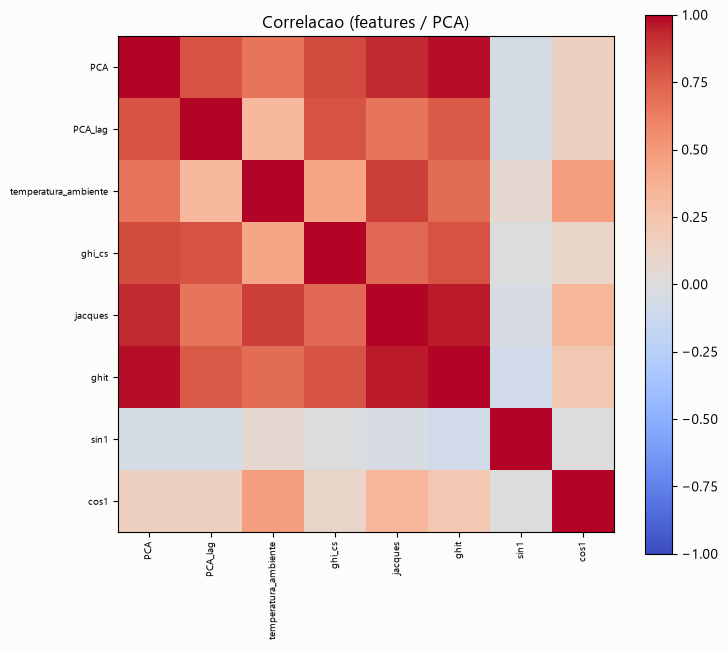

In [68]:
# features selecionadas: as 4 de clima + o ciclo anual
FEATURES_BASE = [
  "temperatura_ambiente",
  "ghi_cs",
  "jacques",
  "ghit",
]
LAG_COLS = ['PCA_lag']

FEATURES = LAG_COLS + FEATURES_BASE + SAZONAIS

show_correlation_map(df, cols_corr =  ["PCA"] + FEATURES)

In [69]:
n_antes = len(df)
# LAG_COLS entram no subset: as 11 primeiras horas da serie nao tem passado, e o
# exogeno do OLS/da rede nao aceita NaN. Sao 11 linhas de 2021, custo irrelevante.
dados = (df.dropna(subset=["PCA", *LAG_COLS])
           .sort_values("datetime").reset_index(drop=True))


treino = dados[dados.datetime.dt.year.between(2021, 2022)].copy()
valid = dados[dados.datetime.dt.year == 2023].copy()
teste = dados[dados.datetime.dt.year == 2024].copy()

print(NL + "splits:")
for nome, d in (("treino", treino), ("validacao", valid), ("teste", teste)):
    print(f"  {nome:10} {len(d):7} linhas  {d['datetime'].min()} .. {d['datetime'].max()}"
          f"  ({100 * len(d) / len(dados):.1f}%)")

# A checagem que importa: nada do futuro no treino.
assert treino["datetime"].max() < valid["datetime"].min(), "treino e validação se sobrepoem no tempo!"
assert valid["datetime"].max() < teste["datetime"].min(), "validação e teste se sobrepoem no tempo!"

# E nenhum NaN nas entradas: um exogeno com NaN passa silenciosamente para o
# treino_random_forest.ipynb e vira NaN na normalizacao z-score.
for nome, d in (("treino", treino), ("validacao", valid), ("teste", teste)):
    faltando = [c for c in LAG_COLS if d[c].isna().any()]
    assert not faltando, f"{nome}: NaN nas defasagens {faltando}"
    sint = int(d["sintetico"].sum())
    print(f"  {nome:10} sinteticos: {sint:4d} ({100 * sint / len(d):.1f}%)")
print(NL + "OK: splits disjuntos no tempo, sem NaN nas defasagens")


splits:
  treino        8301 linhas  2021-01-01 06:00:00 .. 2022-12-31 17:00:00  (50.0%)
  validacao     4157 linhas  2023-01-01 06:00:00 .. 2023-12-31 17:00:00  (25.0%)
  teste         4140 linhas  2024-01-01 06:00:00 .. 2024-12-31 15:00:00  (24.9%)
  treino     sinteticos:  265 (3.2%)
  validacao  sinteticos:    1 (0.0%)
  teste      sinteticos:  221 (5.3%)

OK: splits disjuntos no tempo, sem NaN nas defasagens


In [70]:
# MAE / RMSE / R2 no dataset teste
def avalia(colunas):
    m = sm.OLS(treino["PCA"], sm.add_constant(treino[colunas])).fit()
    # reordena o teste na mesma ordem do ajuste
    p = m.predict(sm.add_constant(teste[m.params.index.drop("const")]))
    e = teste["PCA"] - p
    return tuple(round(float(x), 4) for x in (e.abs().mean(),
                                              np.sqrt((e ** 2).mean()),
                                              1 - (e ** 2).mean() / teste["PCA"].var()))

print("MAE / RMSE / R2")
print("sem sazonalidade:", avalia(FEATURES_BASE))
print("com sazonalidade:", avalia(FEATURES))

MAE / RMSE / R2
sem sazonalidade: (0.1081, 0.1594, 0.9022)
com sazonalidade: (0.1018, 0.1539, 0.9088)


In [71]:
if not OUT_DIR.exists():
  OUT_DIR.mkdir()

# save datasets 
treino.to_csv(OUT_DIR / "train.csv", index=False)
teste.to_csv(OUT_DIR / "test.csv", index=False)
valid.to_csv(OUT_DIR / "validation.csv", index=False)

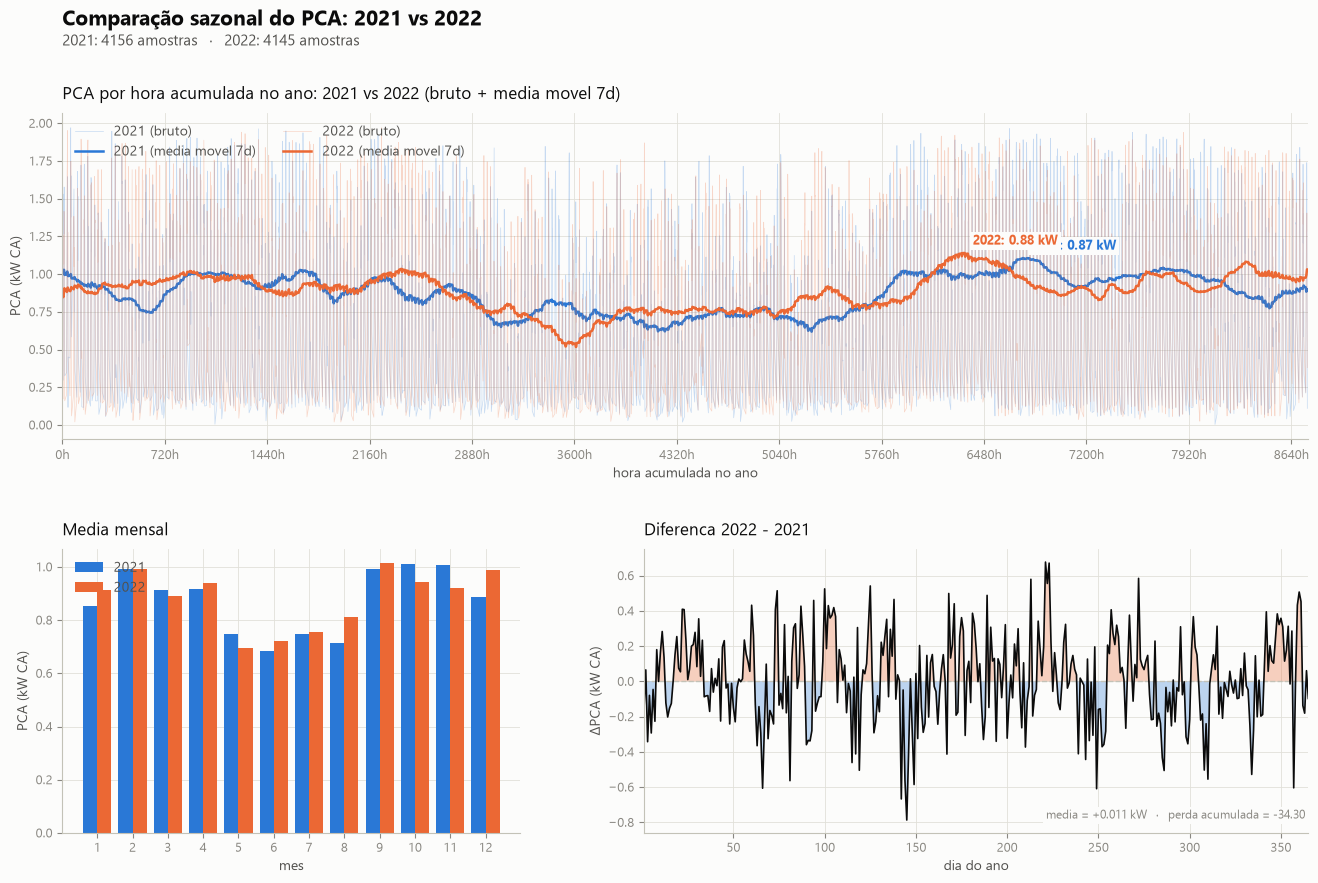

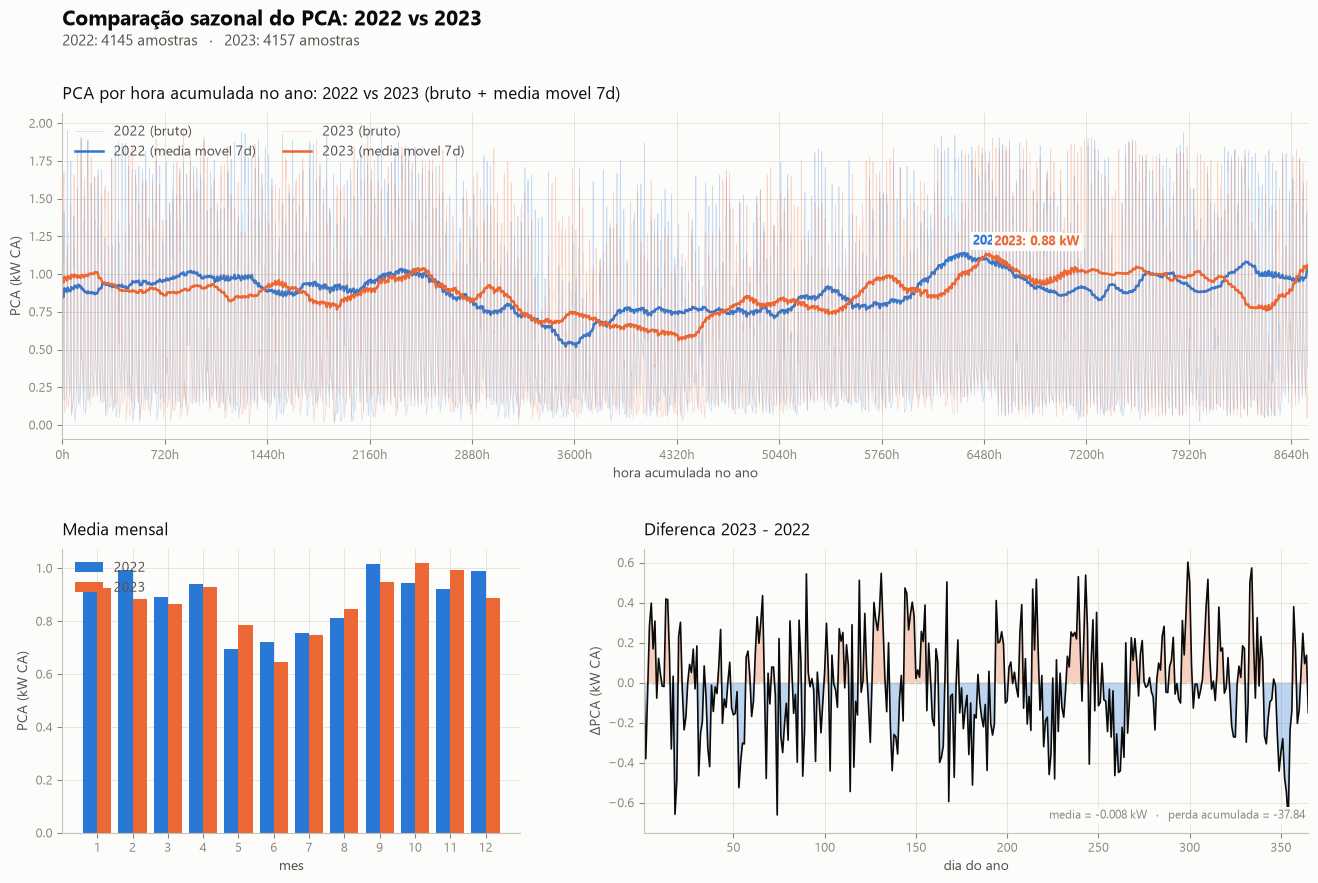

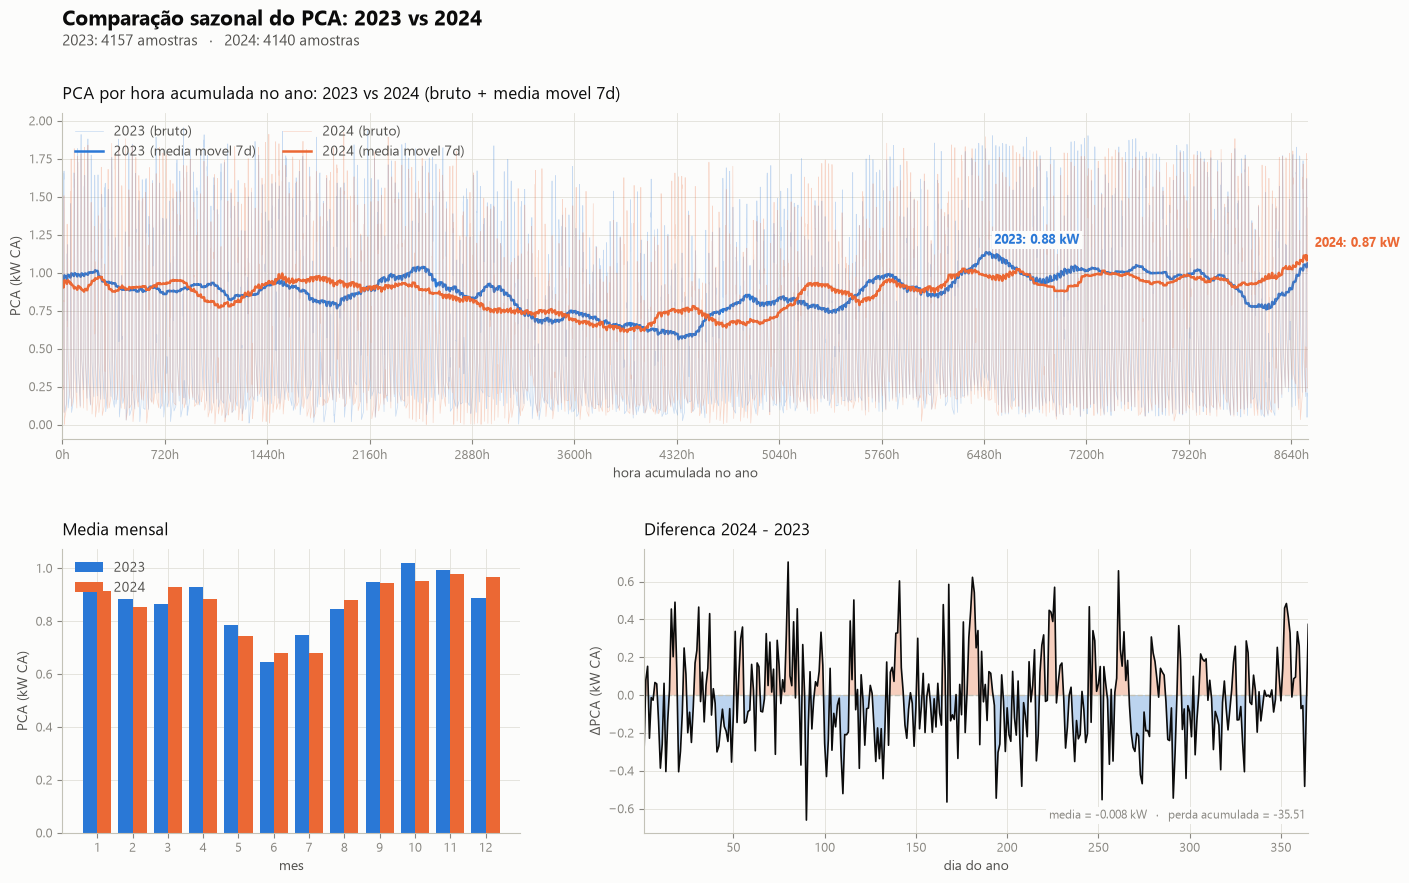

In [72]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

SUPERFICIE, TINTA = "#fcfcfb", "#0b0b0b"
TINTA_2, MUDO     = "#52514e", "#898781"
GRADE, EIXO       = "#e1e0d9", "#c3c2b7"
REAL, PREDITO     = "#2a78d6", "#eb6834"   # slots categoricos 1 e 2
ERRO_CLARO, MAE_ESC = "#86b6ef", "#184f95" # rampa azul: degraus 250 e 600

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "system-ui", "DejaVu Sans"],
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
})

def enfeitar(ax, titulo, xlabel, ylabel):
        ax.set_title(titulo, color=TINTA, fontsize=12, loc="left", pad=10)
        ax.set_xlabel(xlabel, color=TINTA_2, fontsize=10)
        ax.set_ylabel(ylabel, color=TINTA_2, fontsize=10)
        ax.grid(True, color=GRADE, linewidth=0.6, linestyle="-")
        ax.set_axisbelow(True)
        for lado in ("top", "right"):
            ax.spines[lado].set_visible(False)
        for lado in ("left", "bottom"):
            ax.spines[lado].set_color(EIXO)
        ax.tick_params(colors=MUDO, labelsize=9)


def plot_diff_year(start, end):
    df_eval = dados[dados.datetime.dt.year.between(start, end)].copy()
    df_eval = df_eval.reset_index().drop(columns=[c for c in df_eval.columns if c not in ("PCA", "datetime")])

    # --- Comparacao sazonal do PCA: start vs end --------------------------------
    # df_eval tem somente index / datetime / PCA (start-end).
    df_eval["ano"]  = df_eval["datetime"].dt.year
    df_eval["mes"]  = df_eval["datetime"].dt.month
    df_eval["doy"]  = df_eval["datetime"].dt.dayofyear
    df_eval.loc[df_eval["doy"] == 366, "doy"] = 365
    df_eval["hora"] = df_eval["datetime"].dt.hour
    # hora acumulada no ano: hora 0 do dia 1 = 0, ...  (doy-1)*24 + hora
    df_eval["hora_ano"] = (df_eval["doy"] - 1) * 24 + df_eval["hora"]

    cores = {start: REAL, end: PREDITO}
    g_hora = {a: df_eval[df_eval["ano"] == a].groupby("hora")["PCA"] for a in cores}
    g_doy  = {a: df_eval[df_eval["ano"] == a].groupby("doy")["PCA"] for a in cores}
    g_mes  = {a: df_eval[df_eval["ano"] == a].groupby("mes")["PCA"].mean() for a in cores}

    fig = plt.figure(figsize=(14, 9))
    gs = GridSpec(2, 2, figure=fig, height_ratios=[1.15, 1.0], width_ratios=[1.0, 1.45],
                hspace=0.36, wspace=0.22)
    HALO = dict(facecolor=SUPERFICIE, edgecolor="none", pad=2.0)


    # --- 1. curva horaria acumulada ao longo do ano ----------------------------
    # x = hora acumulada no ano (0 .. 8760 h)
    # valor bruto (linha fina) + media movel de 1 semana (linha grossa).
    ax = fig.add_subplot(gs[0, :])
    JANELA = 24 * 7  # 1 semana
    for ano, cor in cores.items():
        d = df_eval[df_eval["ano"] == ano].sort_values("hora_ano").copy()
        # valor bruto
        ax.plot(d["hora_ano"], d["PCA"], color=cor, lw=0.5, alpha=0.25,
                label=f"{ano} (bruto)")
        # media movel
        mm = d["PCA"].rolling(window=JANELA, center=True, min_periods=1).mean()
        ax.plot(d["hora_ano"], mm, color=cor, lw=1.8, label=f"{ano} (media movel 7d)")
        imax = mm.idxmax()
        ax.annotate(f"{ano}: {d['PCA'].mean():.2f} kW",
                    (d["hora_ano"].loc[imax], mm.loc[imax]),
                    xytext=(6, 6), textcoords="offset points",
                    color=cor, fontsize=9, fontweight="bold", bbox=HALO)
    enfeitar(ax, f"PCA por hora acumulada no ano: {start} vs {end} (bruto + media movel 7d)",
            "hora acumulada no ano", "PCA (kW CA)")
    ax.set_xlim(0, 365 * 24)
    ticks = np.arange(0, 365 * 24 + 1, 24 * 30)   # ~a cada 30 dias
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{int(t)}h" for t in ticks])
    ax.legend(frameon=False, loc="upper left", fontsize=10, labelcolor=TINTA_2, ncol=2)

    # --- 2. media mensal: barras emparelhadas ----------------------------------
    ax = fig.add_subplot(gs[1, 0])
    meses = np.arange(1, 13)
    largura = 0.4
    ax.bar(meses - largura / 2, g_mes[start].reindex(meses).values,
        width=largura, color=REAL, label=f"{start}", linewidth=0)
    ax.bar(meses + largura / 2, g_mes[end].reindex(meses).values,
        width=largura, color=PREDITO, label=f"{end}", linewidth=0)
    enfeitar(ax, "Media mensal", "mes", "PCA (kW CA)")
    ax.set_xticks(meses)
    ax.legend(frameon=False, loc="upper left", fontsize=10, labelcolor=TINTA_2)

    # --- 3. diferenca sazonal (end - start) ------------------------------------
    ax = fig.add_subplot(gs[1, 1])
    dif = (g_doy[end].mean().reindex(range(1, 366))
        - g_doy[start].mean().reindex(range(1, 366)))
    ax.axhline(0, color=EIXO, lw=1.0, linestyle="--")
    ax.fill_between(dif.index, 0, dif.values, where=(dif.values >= 0),
                    color=PREDITO, alpha=0.30, linewidth=0, interpolate=True)
    ax.fill_between(dif.index, 0, dif.values, where=(dif.values < 0),
                    color=REAL, alpha=0.30, linewidth=0, interpolate=True)
    ax.plot(dif.index, dif.values, color=TINTA, lw=1.2)
    ax.text(0.995, 0.04,
            f"media = {dif.mean():+.3f} kW   ·   perda acumulada = {dif.clip(upper=0).sum():.2f}",
            transform=ax.transAxes, ha="right", va="bottom",
            color=MUDO, fontsize=8.5, bbox=HALO)
    enfeitar(ax, f"Diferenca {end} - {start}", "dia do ano", "ΔPCA (kW CA)")
    ax.set_xlim(1, 365)

    fig.suptitle(f"Comparação sazonal do PCA: {start} vs {end}", color=TINTA, fontsize=15,
                x=0.07, ha="left", y=0.985, fontweight="bold")
    fig.text(0.07, 0.945,
            f"{start}: {len(df_eval[df_eval.ano == start])} amostras   ·   "
            f"{end}: {len(df_eval[df_eval.ano == end])} amostras",
            color=TINTA_2, fontsize=11, ha="left")
    fig.subplots_adjust(top=0.87, bottom=0.07, left=0.07, right=0.96)
    plt.show()

for y in range(2021, 2024):
    plot_diff_year(y, y+1)


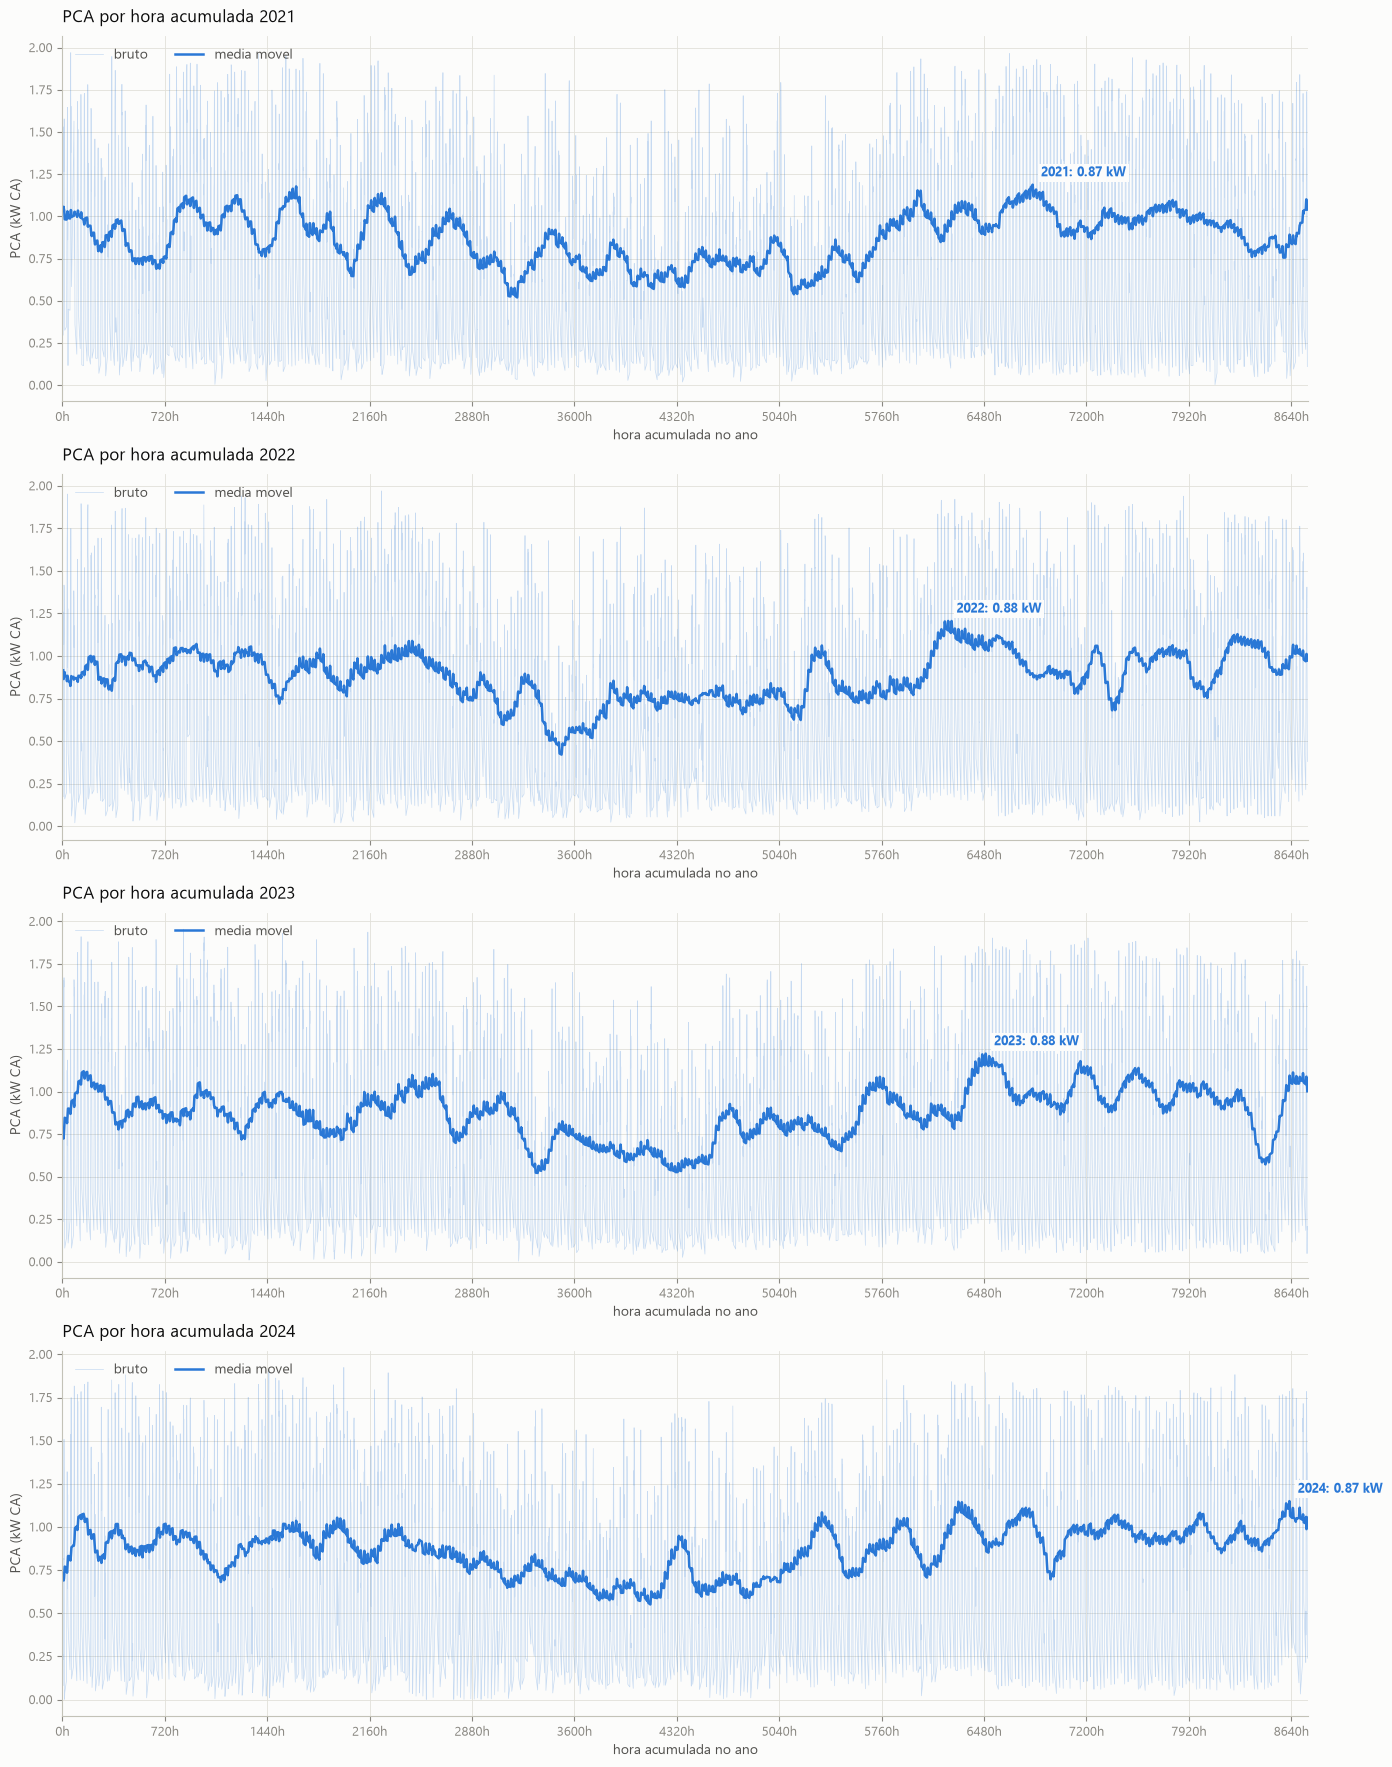

In [73]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

SUPERFICIE, TINTA = "#fcfcfb", "#0b0b0b"
TINTA_2, MUDO     = "#52514e", "#898781"
GRADE, EIXO       = "#e1e0d9", "#c3c2b7"
REAL, PREDITO     = "#2a78d6", "#eb6834"   # slots categoricos 1 e 2
ERRO_CLARO, MAE_ESC = "#86b6ef", "#184f95" # rampa azul: degraus 250 e 600

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "system-ui", "DejaVu Sans"],
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
})

def enfeitar(ax, titulo, xlabel, ylabel):
        ax.set_title(titulo, color=TINTA, fontsize=12, loc="left", pad=10)
        ax.set_xlabel(xlabel, color=TINTA_2, fontsize=10)
        ax.set_ylabel(ylabel, color=TINTA_2, fontsize=10)
        ax.grid(True, color=GRADE, linewidth=0.6, linestyle="-")
        ax.set_axisbelow(True)
        for lado in ("top", "right"):
            ax.spines[lado].set_visible(False)
        for lado in ("left", "bottom"):
            ax.spines[lado].set_color(EIXO)
        ax.tick_params(colors=MUDO, labelsize=9)


def plot_diff_year(*years):
    df_eval = dados.copy()
    df_eval = df_eval.reset_index().drop(columns=[c for c in df_eval.columns if c not in ("PCA", "datetime")])

    # --- Comparacao sazonal do PCA: start vs end --------------------------------
    # df_eval tem somente index / datetime / PCA (start-end).
    df_eval["ano"]  = df_eval["datetime"].dt.year
    df_eval["mes"]  = df_eval["datetime"].dt.month
    df_eval["doy"]  = df_eval["datetime"].dt.dayofyear
    df_eval.loc[df_eval["doy"] == 366, "doy"] = 365
    df_eval["hora"] = df_eval["datetime"].dt.hour
    # hora acumulada no ano: hora 0 do dia 1 = 0, ...  (doy-1)*24 + hora
    df_eval["hora_ano"] = (df_eval["doy"] - 1) * 24 + df_eval["hora"]

   
    HALO = dict(facecolor=SUPERFICIE, edgecolor="none", pad=2.0)


    # --- 1. curva horaria acumulada ao longo do ano ----------------------------
    # x = hora acumulada no ano (0 .. 8760 h)
    # valor bruto (linha fina) + media movel de 1 semana (linha grossa).
    cor = REAL
    fig, ax = plt.subplots(nrows=len(years),figsize=(14, 21))
    
    for i, ano in enumerate(years):
        d = df_eval[df_eval["ano"] == ano].sort_values("hora_ano").copy()
        # valor bruto
        ax[i].plot(d["hora_ano"], d["PCA"], color=cor, lw=0.5, alpha=0.25, label="bruto")
        # media movel
        JANELA = 1 + len(d) // 60
        mm = d["PCA"].rolling(window=JANELA, center=True, min_periods=1).mean()
        ax[i].plot(d["hora_ano"], mm, color=cor, lw=1.8, label="media movel")
        imax = mm.idxmax()
        ax[i].annotate(f"{ano}: {d['PCA'].mean():.2f} kW",
                    (d["hora_ano"].loc[imax], mm.loc[imax]),
                    xytext=(6, 6), textcoords="offset points",
                    color=cor, fontsize=9, fontweight="bold", bbox=HALO)
        enfeitar(ax[i], f"PCA por hora acumulada {ano}", "hora acumulada no ano", "PCA (kW CA)")
        ax[i].set_xlim(0, 365 * 24)
        ticks = np.arange(0, 365 * 24 + 1, 24 * 30)   # ~a cada 30 dias
        ax[i].set_xticks(ticks)
        ax[i].set_xticklabels([f"{int(t)}h" for t in ticks])
        ax[i].legend(frameon=False, loc="upper left", fontsize=10, labelcolor=TINTA_2, ncol=2)

    fig.subplots_adjust(top=0.87, bottom=0.07, left=0.07, right=0.96)
    plt.show()

plot_diff_year(*range(2021, 2025))
